# Wine Quality Prediction

**Aivancity PGE 2 - Machine Learning and Advanced Python**

This notebook follows the steps used in the project: load the local data, inspect and prepare it, compare regression models, and make a prediction.

The red and white CSV files are stored beside this notebook. The original copies are also kept in `data/raw/`. The notebook uses the local files and does not download the data.

The target is `quality`. This is a regression project, so the model predicts a numeric score.


## 1. Load the dataset

The `load_data` function uses the project's data loader to read and validate the two CSV files. First, the code finds the copies stored beside this notebook.


In [1]:
from dataclasses import replace
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from wine_quality.config import load_config
from wine_quality.data import TARGET_COLUMN, WineQualityDataset
from wine_quality.eda import create_eda_plots
from wine_quality.features import create_preprocessor
from wine_quality.models import WineQualityTrainer, split_data
from wine_quality.prediction import WinePredictionInput, predict_quality

config = load_config()
data_dirs = [Path.cwd(), Path.cwd() / "notebooks", config.project_root / "notebooks"]
local_data_dir = next(
    (
        folder
        for folder in data_dirs
        if (folder / "winequality-red.csv").is_file()
        and (folder / "winequality-white.csv").is_file()
    ),
    None,
)
if local_data_dir is None:
    raise FileNotFoundError(
        "Put winequality-red.csv and winequality-white.csv beside this notebook."
    )

config = replace(
    config,
    red_data_path=local_data_dir / "winequality-red.csv",
    white_data_path=local_data_dir / "winequality-white.csv",
)


def load_data(settings):
    """Load and validate the local red and white CSV files."""
    loader = WineQualityDataset(settings)
    return loader.load_raw_data()


def clean_data(data, settings):
    """Remove exact duplicates from a copy of the data."""
    loader = WineQualityDataset(settings)
    return loader.remove_exact_duplicates(data)


def load_example(settings):
    """Load the sample prediction input stored in the project."""
    example_path = settings.project_root / "examples" / "new_case.json"
    return WinePredictionInput.model_validate_json(
        example_path.read_text(encoding="utf-8")
    )


for file_path in [config.red_data_path, config.white_data_path]:
    print(f"Local file: {file_path}")

data = load_data(config)
print("Raw dataset shape:", data.shape)
display(data.head())


Local file: D:\Wine Quality\notebooks\winequality-red.csv
Local file: D:\Wine Quality\notebooks\winequality-white.csv
Raw dataset shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


## 2. Explore and check the data

Check the column types, missing values, duplicate rows and quality scores. `quality` is the target. `wine_type` records whether a row came from the red or white CSV.


Data types:


,dtype
fixed_acidity,float64
volatile_acidity,float64
citric_acid,float64
residual_sugar,float64
chlorides,float64
free_sulfur_dioxide,float64
total_sulfur_dioxide,float64
density,float64
pH,float64
sulphates,float64


Missing cells: 0
Duplicate rows including wine_type: 1177
Duplicate rows ignoring wine_type: 1179
Wine type counts:


,rows
wine_type,
white,4898
red,1599


Quality score counts:


,rows
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


quality_distribution.png


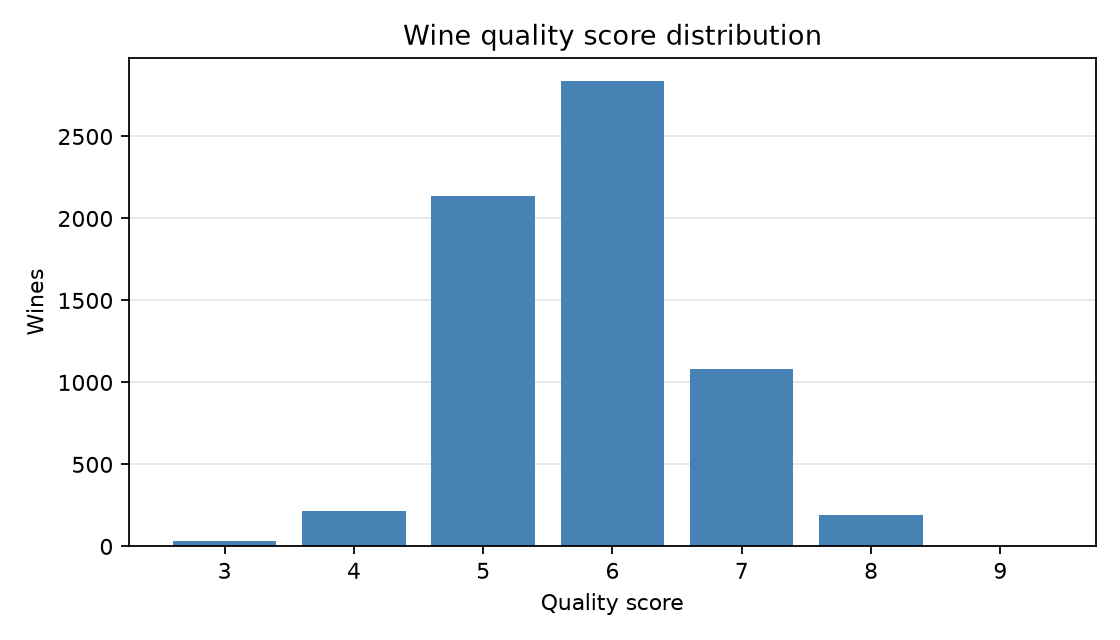

feature_distributions.png


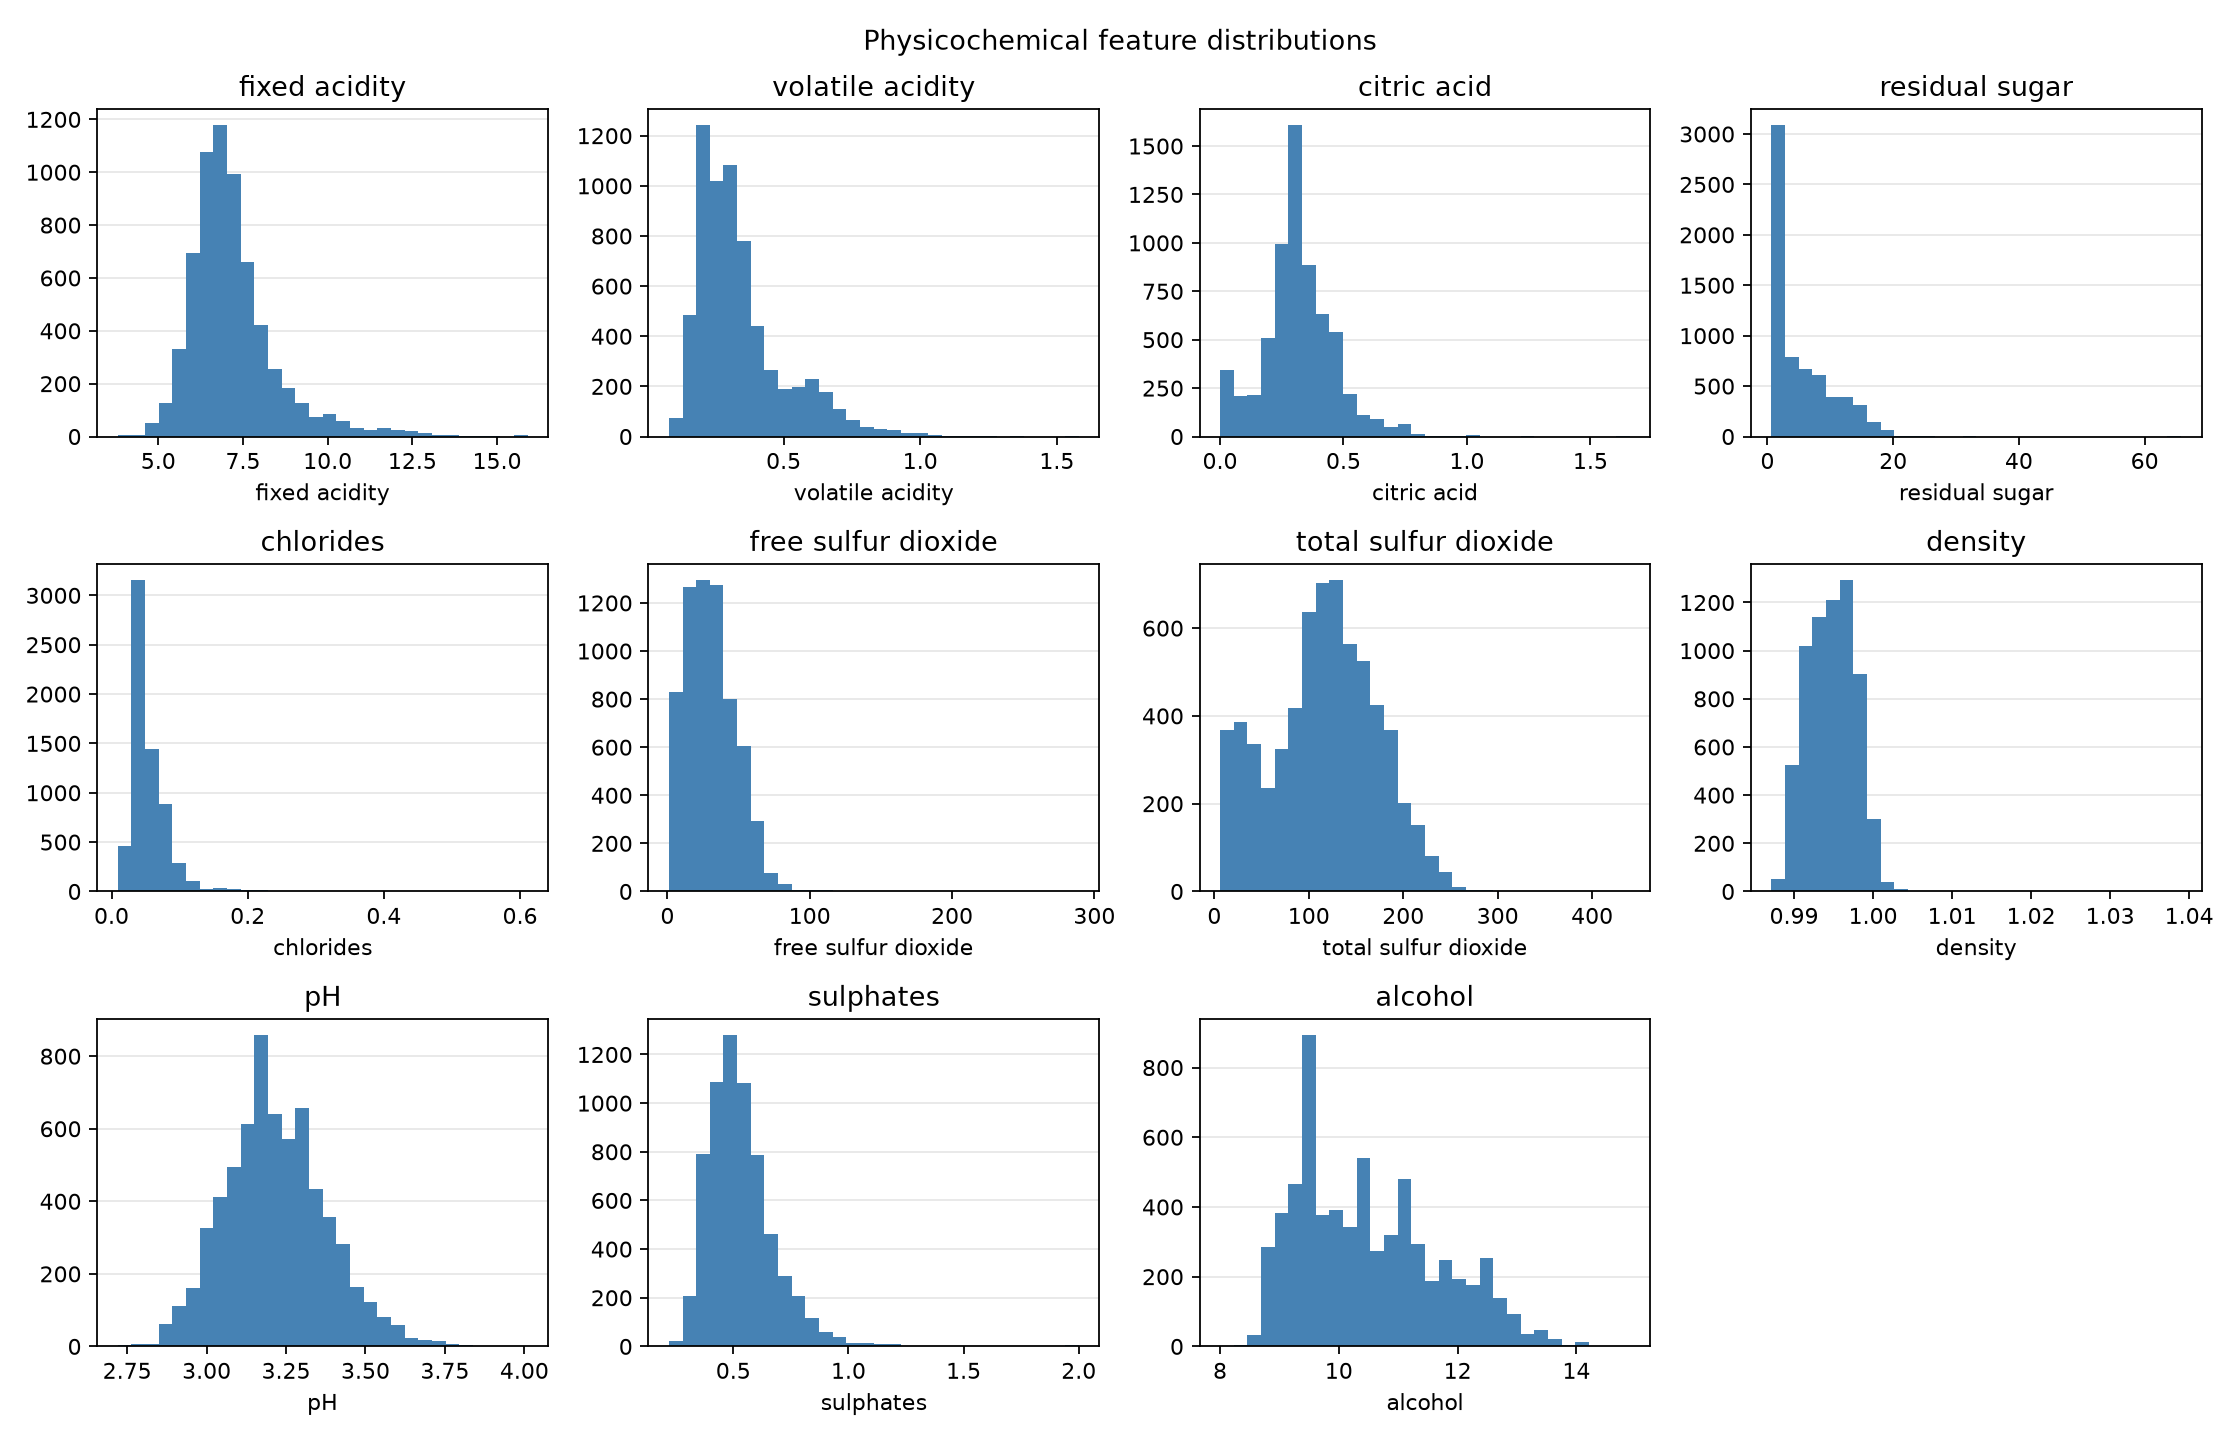

correlation_heatmap.png


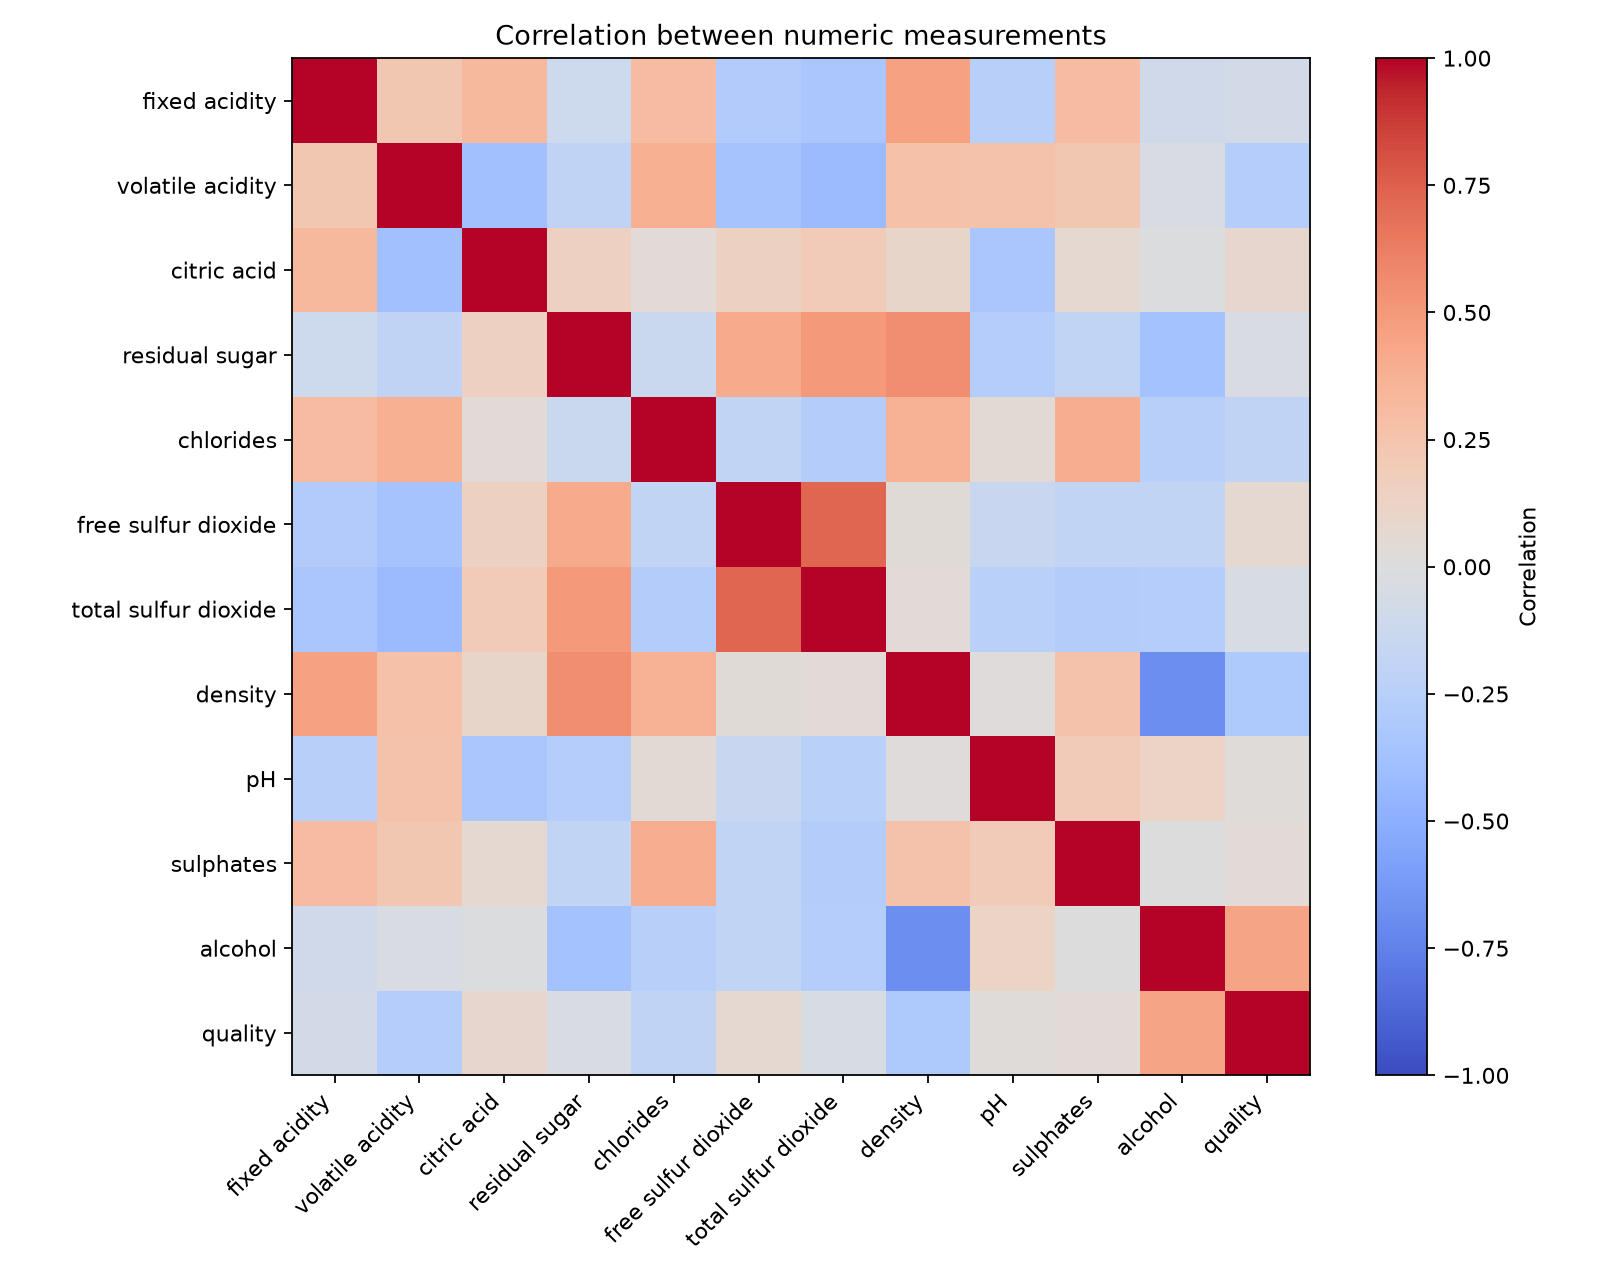

alcohol_vs_quality.png


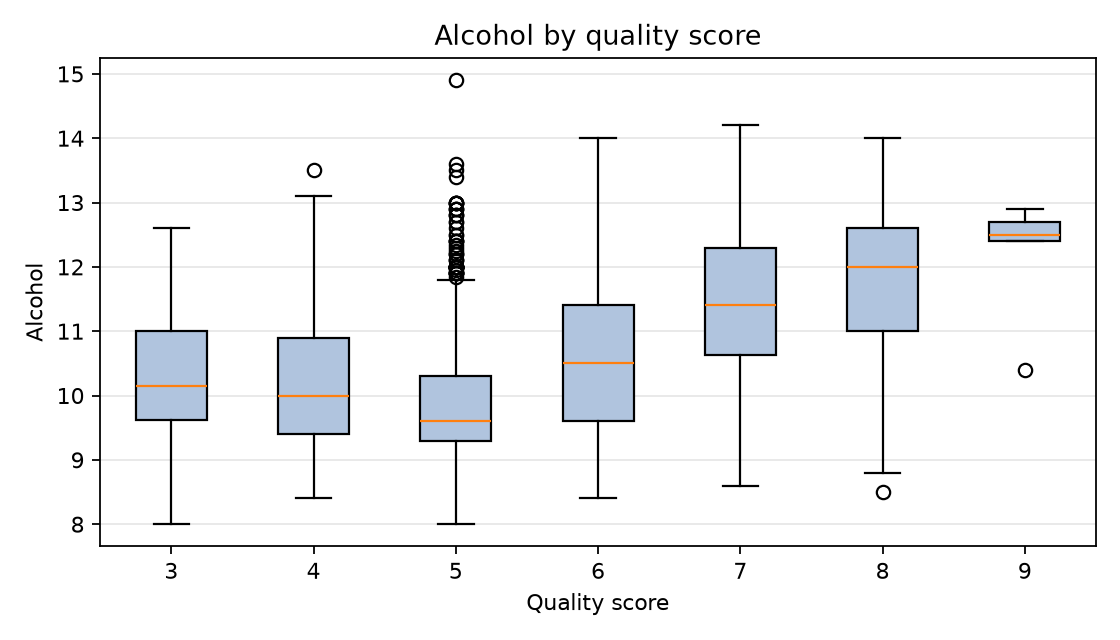

volatile_acidity_vs_quality.png


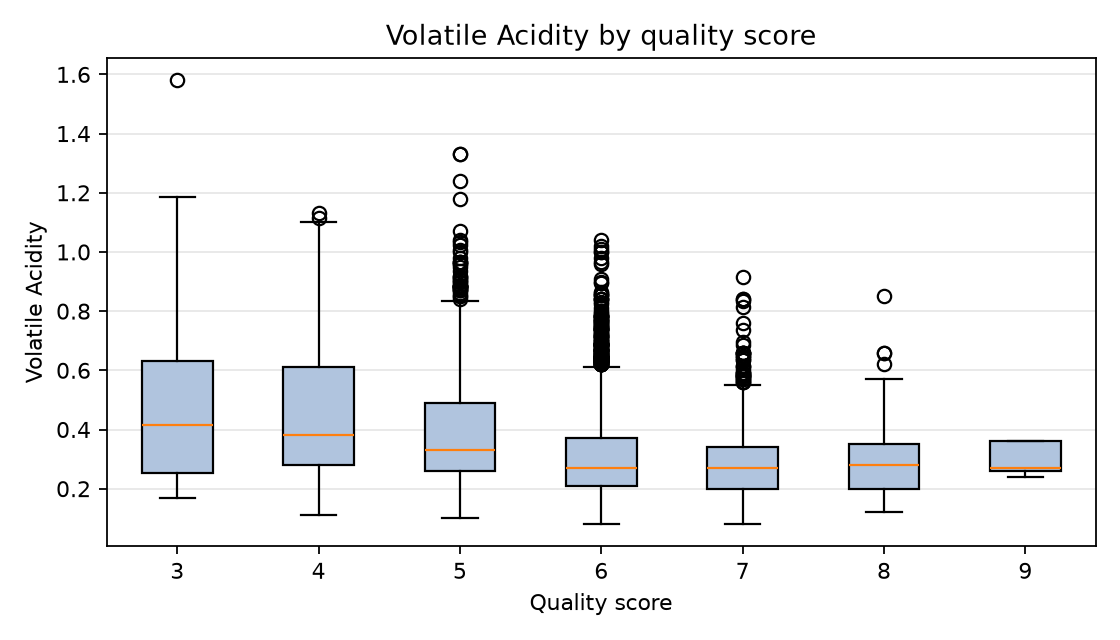

quality_by_wine_type.png


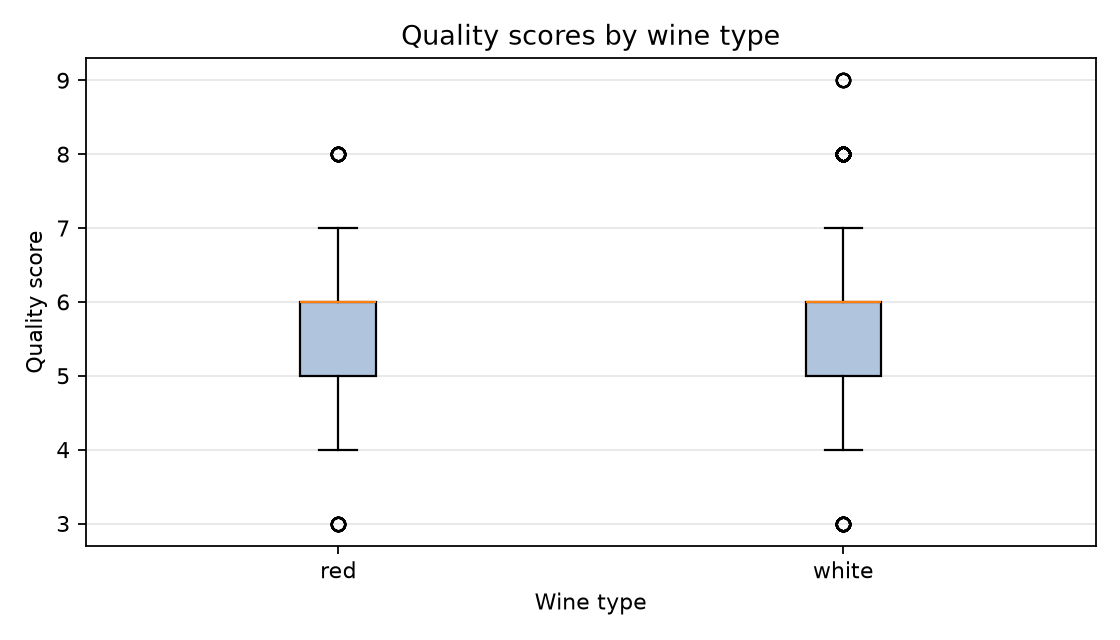

In [2]:
print("Data types:")
display(data.dtypes.rename("dtype").to_frame())
print("Missing cells:", int(data.isna().sum().sum()))
print("Duplicate rows including wine_type:", int(data.duplicated().sum()))
print(
    "Duplicate rows ignoring wine_type:",
    int(data.drop(columns="wine_type").duplicated().sum()),
)
print("Wine type counts:")
display(data["wine_type"].value_counts().rename("rows").to_frame())
print("Quality score counts:")
display(data[TARGET_COLUMN].value_counts().sort_index().rename("rows").to_frame())

plot_paths = create_eda_plots(data, config.figures_dir)
for plot_path in plot_paths:
    print(plot_path.name)
    display(Image(filename=str(plot_path)))


The raw files contain 6,497 rows and no missing cells. Quality scores 5 and 6 occur most often. The charts below show feature distributions, correlations and differences by wine type. Correlations are associations, not evidence of cause and effect.


## 3. Clean and split the data

Remove exact duplicate rows, then make one 80/20 train/test split. The test rows stay aside until the model has been selected.


In [3]:
cleaned_data, duplicate_count = clean_data(data, config)
config.processed_data_path.parent.mkdir(parents=True, exist_ok=True)
cleaned_data.to_csv(config.processed_data_path, index=False)

X_train, X_test, y_train, y_test = split_data(cleaned_data, config)
print("Rows removed:", duplicate_count)
print("Clean data shape:", cleaned_data.shape)
print("Training rows:", len(X_train))
print("Test rows held aside:", len(X_test))
print("Train/test index overlap:", len(X_train.index.intersection(X_test.index)))


Rows removed: 1177
Clean data shape: (5320, 13)
Training rows: 4256
Test rows held aside: 1064
Train/test index overlap: 0


## 4. Preprocessing and leakage prevention

Numeric columns are imputed with their median and standardized. The categorical `wine_type` column is imputed and one-hot encoded. The next cell shows the transformation on the training data, then applies the learned transformation to the test data.


In [4]:
preprocessor = create_preprocessor()
X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)
print("Transformed training shape:", X_train_ready.shape)
print("Transformed test shape:", X_test_ready.shape)


Transformed training shape: (4256, 13)
Transformed test shape: (1064, 13)


The preprocessor is fitted on `X_train` only. In the model comparison below, preprocessing is inside each scikit-learn Pipeline, so each cross-validation fold learns its own medians and scaling values from that fold's training rows.


## 5. Baseline, model comparison and tuning

The project compares a mean `DummyRegressor` with LinearRegression, Ridge, Lasso, k-NN and LinearSVR. GridSearchCV tunes the model settings using five-fold cross-validation on the training data.


In [5]:
def train_models(settings):
    """Compare and tune the regression models."""
    trainer = WineQualityTrainer(settings)
    return trainer.train()


training_summary = train_models(config)
comparison = pd.DataFrame(training_summary["model_comparison"])
display(comparison.drop(columns="best_params").round(3))
print("Selected model:", training_summary["selected_model"])
print("Selected parameters:", training_summary["selected_parameters"])


,model,cv_rmse,cv_mae,cv_r2
0,KNeighborsRegressor,0.715,0.553,0.343
1,Ridge,0.735,0.567,0.306
2,LinearRegression,0.735,0.567,0.306
3,Lasso,0.735,0.567,0.305
4,LinearSVR,0.737,0.566,0.302
5,DummyRegressor,0.883,0.697,-0.002


Selected model: KNeighborsRegressor
Selected parameters: {'model__n_neighbors': 21, 'model__weights': 'distance'}


The model is selected by its mean cross-validation RMSE. The test-set results do not affect this choice. The mean `DummyRegressor` provides a simple baseline for comparison.


## 6. Final test evaluation

Now report the scores on the untouched test set. The baseline and selected model use the same test rows.


In [6]:
print("Selected model test metrics:", training_summary["test_metrics"])
print("Mean baseline test metrics:", training_summary["baseline_test_metrics"])


Selected model test metrics: {'rmse': 0.6853871834952694, 'mae': 0.5344601613765455, 'r2': 0.3752184575637113}
Mean baseline test metrics: {'rmse': 0.8675790772750018, 'mae': 0.6942255780428516, 'r2': -0.0010928804463392616}


## 7. Interpret the selected model

Permutation importance measures how much the model's test score changes when one feature is shuffled. It describes the fitted model, not a causal relationship.


,feature,importance_mean,importance_std
0,alcohol,0.1082,0.0063
1,volatile_acidity,0.0389,0.0047
2,free_sulfur_dioxide,0.0356,0.0033
3,sulphates,0.0333,0.0026
4,total_sulfur_dioxide,0.0329,0.0042
5,density,0.0241,0.0039
6,chlorides,0.0239,0.0036
7,residual_sugar,0.0234,0.0013


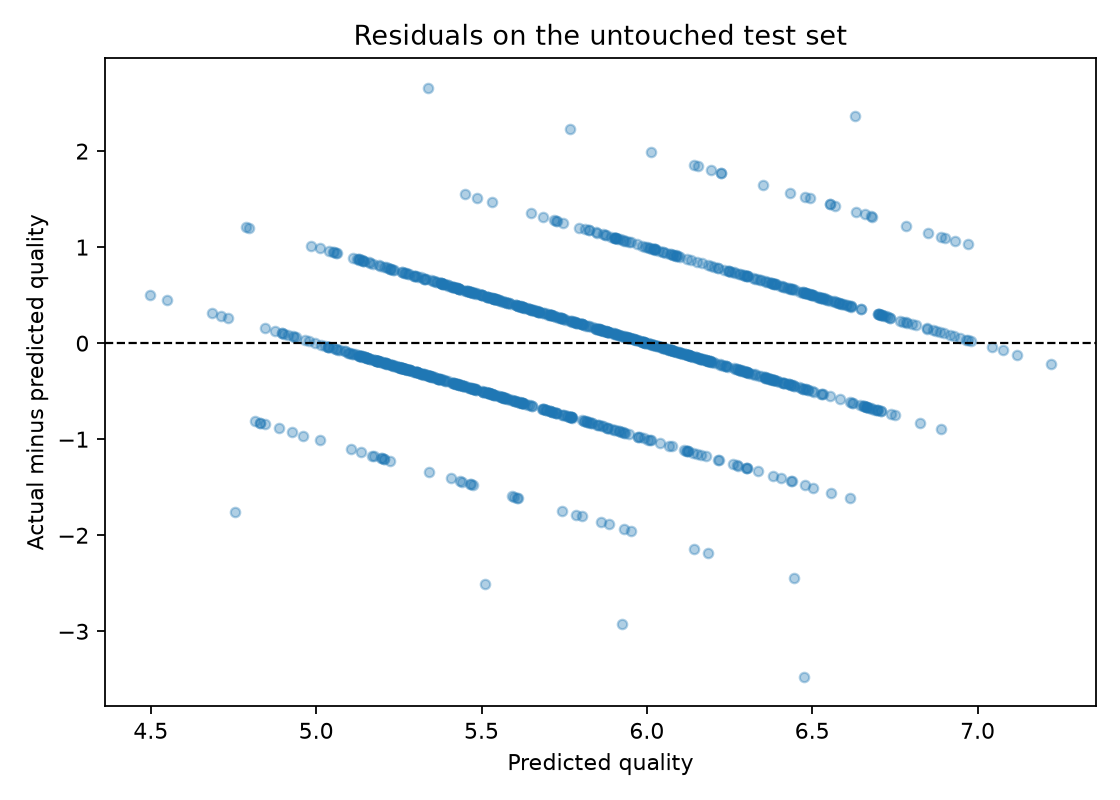

In [7]:
importance = pd.DataFrame(training_summary["feature_importance"])
display(importance.head(8).round(4))
display(Image(filename=str(config.figures_dir / "test_residuals.png")))


RMSE and MAE are measured in quality-score points. RMSE gives larger errors more weight; MAE is the average absolute error. R-squared compares the predictions with a mean prediction. Permutation importance is for interpretation only and is not used to tune the model.


## 8. Predict one new example

The example input is a local JSON file in `examples/`. The same saved preprocessing and model are used for prediction.


In [8]:
example = load_example(config)
prediction = predict_quality(example, config)
print(f"Predicted quality: {prediction:.2f} out of 10")


Predicted quality: 5.67 out of 10


## 9. Limits and conclusion

The model predicts a tasting score; it does not replace a tasting. The score is ordinal, even though regression treats it as numeric. The data describe Portuguese Vinho Verde wines and do not include details such as grape variety, brand, price or tasting conditions. The final test score is an estimate for this dataset and may not carry over to other wines.
